# 01 · Train MiniBatch K-Means on network records

**Goal.** Group network records by similarities in their measured features. First try several
values of K on a small training sample, then train one finalist per scaling on the entire TRAIN split.

Open **02 · Evaluate** once this notebook finishes.

### What are we training?

- A **record** is one row. A **feature** is one numeric measurement in a column.
  `X` is the table of feature values. `y` usually means the known class for each row.
- **K** is the number of centers to learn. K-Means assigns each record to the closest center
  in Euclidean distance and updates the centers so they represent their assigned records.
  For two features, picture dots on a graph and a movable marker at each group's middle.
- **MiniBatch K-Means** moves the centers using a small batch of records at a time. This lets
  us process about 4.9 million training rows in bounded memory. The result can vary with batch
  order and how the centers start. The `fit` and `partial_fit` calls below receive only `X`.

Read README.md for setup guide.

## 1. Read settings and limit CPU threads

A JSON file stores settings as name - value pairs. Here we read the thread budget first and give
it to numeric libraries before importing them. A Python `for` loop repeats the same assignment
for each library setting in the list.

In [1]:
import json
import os
from pathlib import Path

CONFIG_FILE = Path("experiment_config.json")
settings = json.loads(CONFIG_FILE.read_text(encoding="utf-8"))
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = str(settings["threads"])

## 2. Import the tools and locate this run

`import` makes a library's tools available. NumPy works with numeric arrays, pandas makes
readable tables, and scikit-learn supplies the model and metrics. The kit's `clustering_utils.py`
takes care of package verification, reading batches, and writing files.

In [2]:
import numpy as np
import pandas as pd
from sklearn import config_context
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from threadpoolctl import threadpool_limits

from itertools import product
from time import perf_counter

from sklearn.cluster import MiniBatchKMeans, kmeans_plusplus

from dataset_source import prepare_package
from clustering_utils import (
    best_within_scaling, comparison_policy, completed_runs, freeze_json, geometry_record,
    load_validation_sample, open_package, plot_silhouette, prepare_cache, read_config,
    read_json, save_geometry, shuffled_batches, start_stage, train_and_save, write_json,
)

cfg = read_config(CONFIG_FILE)
experiment = Path(cfg["output_root"]) / cfg["experiment_id"]
pilot_dir, full_dir = experiment / "pilot", experiment / "full"
print("Output folder", experiment)

Output folder /home/hembegur/Documents/Swin/cos30049_Inno_Proj/G3B_Clustering_Notebook_Kit_Drive_Import/outputs/clustering_001


## 3. Get the dataset

`settings.get("drive_url", "")` reads the saved Drive link. The helper downloads and
extracts the package the first time. It checks the package manifest against the hash
in the dataset handoff before installing the local copy. Later runs reuse that copy.

The first download is several GiB. Watch this cell for transfer and extraction progress.

In [3]:
prepare_package(cfg, settings.get("drive_url", "https://drive.google.com/file/d/1D6sXnp8l7-7YwBaonKoTZKcPG1ULKAuL/view?usp=drive_link"))

Using local dataset package at /home/hembegur/Documents/Swin/cos30049_Inno_Proj/g3b_primary_v1


PosixPath('/home/hembegur/Documents/Swin/cos30049_Inno_Proj/g3b_primary_v1')

### Verify the package and prepare the same samples for every candidate

`open_package` verifies the files and opens the dataset through the supplied loader.

We use all **115 numeric predictors** in their original order. IDs and known security classes
stay outside the feature matrix. TRAIN supplies the data to fit on. VALIDATION supplies
features for model comparison. TEST stays outside the experiment.

Distance depends on units. A feature ranging from 0 to 10,000 can dominate one ranging from
0 to 1. The primary experiment uses the dataset's existing TRAIN-only standardization, which centers
and rescales features using training statistics. The **raw** experiment leaves the original
units intact so we can see how scaling affects the groups.

The default pilot takes 100,000 randomly chosen TRAIN rows. Geometry evaluation uses 10,000
randomly chosen VALIDATION rows. The fixed sample seed makes the row choices repeatable.
The helper saves the row indices and reads feature arrays in pieces. Dataset verification and the
first pass to build the cache may take time.

In [4]:
print("Verifying the dataset and opening TRAIN and VALIDATION.", flush=True)
package, identity = open_package(cfg)
cache = prepare_cache(package, cfg, identity, experiment)

shapes = {split: info["shape"] for split, info in identity["partitions"].items()}
display(pd.DataFrame(shapes, index=["rows", "features"]).T)
for split in ("TRAIN", "VALIDATION"):
    sample = np.load(cache / f"{split}_indices.npy", mmap_mode="r")
    print(split, "sample rows", f"{len(sample):,}")

Verifying the dataset and opening TRAIN and VALIDATION.


,rows,features
TRAIN,4944968,115
VALIDATION,1056372,115


TRAIN sample rows 100,000
VALIDATION sample rows 10,000


## 4. Fit the pilot models

The defaults try **K = 2, 4, 8, 12**. Two gives a coarse grouping, and the larger values let
the model split broad groups into finer ones. These are experiment settings. The true class
count does not determine K.

`def` gives a reusable block of code a name. This function receives one specification
(`spec`, a dictionary containing K, seed, and scaling) and its feature sample. The **seed**
controls randomness. `k-means++` picks spread-out starting centers. `n_init` controls how
many candidate initializations the pilot considers. The model learns when we call `.fit(X_pilot)`.

In [5]:
def fit_pilot(spec, X_pilot, log_event):
    model = MiniBatchKMeans(
        n_clusters=spec["k"], random_state=spec["seed"], batch_size=cfg["batch_size"],
        init="k-means++", n_init=cfg["pilot_n_init"], max_iter=cfg["pilot_max_iter"],
        max_no_improvement=20, reassignment_ratio=cfg["reassignment_ratio"], compute_labels=False,
    )
    model.fit(X_pilot)
    log_event("pilot_fit_complete", unique_fit_rows=len(X_pilot),
              minibatch_updates=int(model.n_steps_))
    return model, len(X_pilot)

Each combination of scaling, K, and seed gets its own model and output folder. A completed
stage with matching configuration and model hashes can be reused. Choose a new
`experiment_id` to train again or to recover after an interrupted stage.

In [6]:
pilot_specs = [
    {"scaling": scaling, "k": k, "seed": seed}
    for scaling, k, seed in product(cfg["scalings"], cfg["k_values"], cfg["seeds"])
]
pilot_cfg = {**cfg, "stage": "pilot"}
pilot_runs = completed_runs(pilot_dir, pilot_cfg, identity, pilot_specs)

if pilot_runs is None:
    start_stage(pilot_dir, pilot_cfg, identity)
    with threadpool_limits(limits=cfg["threads"]):
        pilot_runs = [
            train_and_save(pilot_dir, pilot_cfg, identity, package, cache, spec, fit_pilot)
            for spec in pilot_specs
        ]
    write_json(pilot_dir / "run_index.json", pilot_runs)

display(pd.DataFrame(pilot_runs)[["run_id", "unique_fit_rows", "fit_seconds"]])

Saved standard_k2_seed42 (0.17 seconds to fit)
Saved standard_k4_seed42 (0.09 seconds to fit)
Saved standard_k8_seed42 (0.10 seconds to fit)
Saved standard_k12_seed42 (0.13 seconds to fit)
Saved raw_k2_seed42 (0.09 seconds to fit)
Saved raw_k4_seed42 (0.30 seconds to fit)
Saved raw_k8_seed42 (0.16 seconds to fit)
Saved raw_k12_seed42 (0.18 seconds to fit)


,run_id,unique_fit_rows,fit_seconds
0,standard_k2_seed42,100000,0.167210
1,standard_k4_seed42,100000,0.085939
2,standard_k8_seed42,100000,0.101395
3,standard_k12_seed42,100000,0.125781
4,raw_k2_seed42,100000,0.090316
5,raw_k4_seed42,100000,0.295857
6,raw_k8_seed42,100000,0.156697
7,raw_k12_seed42,100000,0.182994


## 5. Score the pilot and save two finalists

**Silhouette** measures how close a row is to its own cluster compared with the closest other
cluster. Scores range from −1 to 1. A positive value suggests a better fit to its assigned
group, near zero suggests overlap, and a negative value suggests the row is closer on average
to another group.

Computing pairwise distances for millions of rows is expensive. The default runs silhouette
on three saved subsets of 1,500 rows drawn from the same VALIDATION sample. Each candidate
gets the same subsets. If a subset represents only one cluster, or every row is its own cluster,
silhouette is undefined. `None` records an undefined score and the run needs all repeats to
be eligible. The standard deviation shows how much the scores vary across the subsets.

In [7]:
def score_silhouette(X, clusters, item):
    details = []
    for repeat in range(cfg["silhouette_repeats"]):
        positions = np.load(cache / f"silhouette_positions_{repeat}.npy")
        labels = clusters[positions]
        represented = len(np.unique(labels))
        valid = 2 <= represented < len(positions)
        score = float(silhouette_score(X[positions], labels)) if valid else None
        if score is not None and not np.isfinite(score):
            raise ValueError("Non-finite silhouette")
        details.append({
            "run_id": item["run_id"], "repeat": repeat, "rows": len(positions),
            "represented_clusters": represented, "requested_k": item["k"],
            "score": score, "reason": None if valid else "need 2 <= clusters < rows",
        })
    return details

The next cell measures all saved models. **Davies–Bouldin** (DBI, smaller is better) and
**Calinski–Harabasz** (CH, larger is better) summarize within-group spread and between-group
separation on the 10,000-row sample. We also record the average squared distance to the
learned centers. The distance units depend on the scaling.

In [8]:
def measure_geometry(stage_dir, runs):
    rows, all_details = [], []
    with threadpool_limits(limits=cfg["threads"]), config_context(working_memory=64):
        for item in runs:
            model, X, clusters = load_validation_sample(cache, stage_dir, item)
            details = score_silhouette(X, clusters, item)
            valid = 2 <= len(np.unique(clusters)) < len(X)
            dbi = float(davies_bouldin_score(X, clusters)) if valid else None
            ch = float(calinski_harabasz_score(X, clusters)) if valid else None
            difference = X - model.cluster_centers_[clusters]
            mean_distance = float(np.einsum("ij,ij->", difference, difference) / len(X))
            rows.append(geometry_record(cfg, stage_dir, item, X, clusters,
                                        details, dbi, ch, mean_distance))
            all_details.extend(details)
    return save_geometry(stage_dir, rows, all_details)

,run_id,requested_k,silhouette_mean,silhouette_sample_std,davies_bouldin,calinski_harabasz,selection_eligible
0,standard_k2_seed42,2,0.525235,0.005167,0.943095,3918.070323,True
1,standard_k4_seed42,4,0.551646,0.021716,0.675448,2800.578812,True
2,standard_k8_seed42,8,0.608706,0.013844,0.685998,4161.760756,True
3,standard_k12_seed42,12,0.542216,0.008154,1.136851,3015.937248,True
4,raw_k2_seed42,2,0.993532,0.001531,0.212092,152154.176410,True
5,raw_k4_seed42,4,0.996943,0.001685,0.399892,218917.250168,True
6,raw_k8_seed42,8,0.996414,0.001992,0.589616,527203.600757,True
7,raw_k12_seed42,12,0.995171,0.001664,0.472649,668036.301161,True


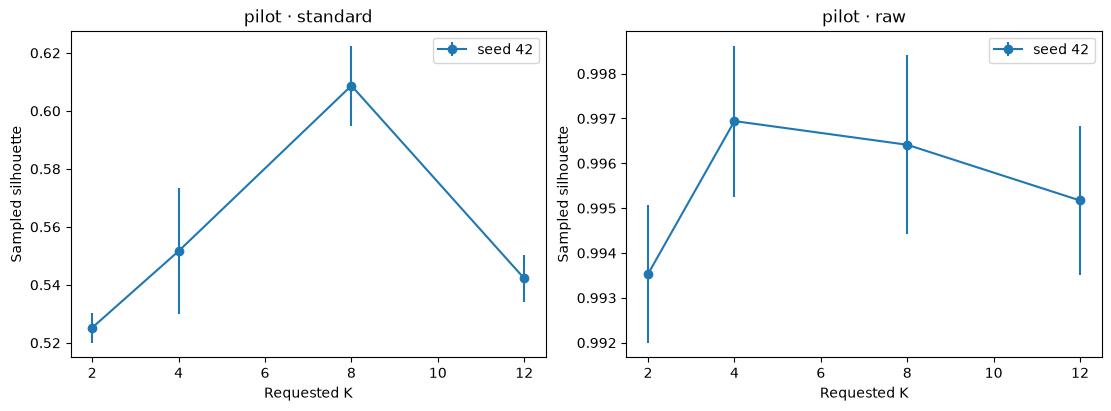

In [9]:
pilot_table = measure_geometry(pilot_dir, pilot_runs)
display(pilot_table[["run_id", "requested_k", "silhouette_mean", "silhouette_sample_std",
                     "davies_bouldin", "calinski_harabasz", "selection_eligible"]])
plot_silhouette(pilot_dir, pilot_table, cfg["scalings"])

We rank each scaling separately by mean silhouette rounded to six decimal places. Ties favor
smaller K, then smaller seed. We save those two settings in `pilot/full_plan.json` so the next
step can use the exact same choices. Security labels play no part in this ranking.

In [10]:
finalists = []
for scaling in cfg["scalings"]:
    best = best_within_scaling(pilot_table, scaling)
    finalists.append({"scaling": scaling, "k": int(best["requested_k"]), "seed": int(best["seed"])})

plan = {
    "identity": identity, "comparison_policy": comparison_policy(cfg), "finalists": finalists,
    "rule": "within each scaling, max silhouette rounded to 6 decimals, then smaller K, then seed",
    "ground_truth_used": False,
}
freeze_json(pilot_dir / "full_plan.json", plan)
display(pd.DataFrame(finalists))

,scaling,k,seed
0,standard,8,42
1,raw,4,42


## 6. Train the finalists on every TRAIN row

A finalist specifies **which settings to use**. We create a fresh model for the full fit.
Its starting centers come from `k-means++` on a small subset of the cached TRAIN sample.
A NumPy random number generator picks those positions using the run's seed.

In [11]:
def make_full_model(spec, X_pilot):
    rng = np.random.default_rng(spec["seed"])
    size = min(len(X_pilot), cfg["initialization_rows"])
    positions = rng.choice(len(X_pilot), size, replace=False)
    centers, _ = kmeans_plusplus(
        X_pilot[positions], n_clusters=spec["k"], random_state=spec["seed"])
    return MiniBatchKMeans(
        n_clusters=spec["k"], init=centers, n_init=1, random_state=spec["seed"],
        batch_size=cfg["batch_size"], compute_labels=False,
        reassignment_ratio=cfg["reassignment_ratio"],
    )

An **epoch** is one pass through TRAIN. The outer loop runs an epoch twice by default. The
inner loop reads one batch at a time. `.partial_fit(X_batch)` updates the *same* model with
that batch. The helper shuffles within a fixed-size buffer to limit memory use, so records
from distant parts of TRAIN may remain far apart in the batch order. We count rows to verify
each epoch covers all of TRAIN.

In [12]:
def fit_full(spec, X_pilot, log_event):
    started = perf_counter()
    model = make_full_model(spec, X_pilot)
    train_rows = identity["partitions"]["TRAIN"]["shape"][0]
    for epoch in range(cfg["full_epochs"]):
        seen = 0
        batches = shuffled_batches(package, spec["scaling"], cfg["batch_size"],
                                   cfg["shuffle_buffer_batches"], spec["seed"] + epoch)
        for X_batch in batches:
            model.partial_fit(X_batch)
            seen += len(X_batch)
        if seen != train_rows:
            raise AssertionError("Did not fit on every TRAIN row")
        log_event("epoch_complete", epoch=epoch + 1, rows=seen,
                  elapsed_seconds=perf_counter() - started)
        print(spec["scaling"], "epoch", epoch + 1, "rows", f"{seen:,}", flush=True)
    return model, train_rows

After the last update, the helper calls `.predict(X)` in batches to assign **every TRAIN and
VALIDATION row** to its nearest final center. Predicting leaves the centers fixed. The
assignments keep the original row order so notebook 02 can compare them with the correct labels.
Each run writes a model, its cluster centers, assignments, settings, and training log.
This step can take much longer than the pilot.

In [13]:
full_cfg = {**cfg, "stage": "full"}
full_runs = completed_runs(full_dir, full_cfg, identity, finalists)

if full_runs is None:
    start_stage(full_dir, full_cfg, identity)
    write_json(full_dir / "input_full_plan.json", plan)
    with threadpool_limits(limits=cfg["threads"]):
        full_runs = [
            train_and_save(full_dir, full_cfg, identity, package, cache, spec, fit_full)
            for spec in finalists
        ]
    write_json(full_dir / "run_index.json", full_runs)

if read_json(full_dir / "input_full_plan.json") != plan:
    raise ValueError("Saved full run used a different pilot plan. Use a new experiment_id.")

display(pd.DataFrame(full_runs)[["run_id", "unique_fit_rows", "fit_seconds"]])
print("Training complete. Next, run 02_Evaluation.ipynb.")

standard epoch 1 rows 4,944,968
standard epoch 2 rows 4,944,968
Saved standard_k8_seed42 (24.79 seconds to fit)
raw epoch 1 rows 4,944,968
raw epoch 2 rows 4,944,968
Saved raw_k4_seed42 (12.27 seconds to fit)


,run_id,unique_fit_rows,fit_seconds
0,standard_k8_seed42,4944968,24.786379
1,raw_k4_seed42,4944968,12.266891


Training complete. Next, run 02_Evaluation.ipynb.


### Outputs

| Where | Purpose |
|---|---|
| `pilot/internal_comparison.csv` | Which K scored best within each scaling and how much the scores varied |
| `pilot/full_plan.json` | The two sets of settings that advanced to the full fit |
| `full/<run_id>/training.jsonl` | The rows seen per epoch and the saved-model reload check |
| `full/<run_id>/model.joblib` and `cluster_centers.npy` | The learned model and the location of every center |
| `full/<run_id>/{TRAIN,VALIDATION}_clusters.npy` | One integer cluster ID per original record |
| `full/<run_id>/prediction_coverage.json` | Assignment counts and file fingerprints for each split |

Cluster IDs are arbitrary numbers. For example, `cluster_id = 1` means the record was closest
to center 1. Notebook 02 checks whether that grouping has any relationship to benign/malicious
labels. Two epochs and one seed give a practical starting budget. Claims about convergence
or seed stability would require additional experiments.